<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/WeeklyModules/Week09/PARTICIPATION_ACTIVITY_Week_9_Fetch_a_website's_content_and_extract_text_from_it.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Participation Activity — Image Downloader
**MSSP 607** · Zhiyu Guo

## 1. Setup

In [1]:
# Mount Google Drive so the images and CSV are saved permanently (same setup as the Week 9 lecture)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%pushd "/content/drive/MyDrive/MSSP607/Modules/Week09/"

/content/drive/MyDrive/MSSP607/Modules/Week09


['/content']

In [3]:
import os
import re
import time

import requests
import bs4
import pandas as pd

# Category to search for — change this to try another one
SEARCH_TAG = 'lighthouse'

# Folder the images will be saved into
SAVE_DIR = f'flickr_{SEARCH_TAG}'
os.makedirs(SAVE_DIR, exist_ok=True)

# Identify the script politely; some sites reject requests with no User-Agent
HEADERS = {'User-Agent': 'MSSP607-Week9-ImageDownloader (educational use)'}

## 2. Search the photo site
Flickr's public feed returns the most recent public photos with a given tag. Asking for `format=json&nojsoncallback=1` returns plain JSON instead of JavaScript.

In [4]:
FEED_URL = 'https://www.flickr.com/services/feeds/photos_public.gne'
params = {
    'tags': SEARCH_TAG,
    'format': 'json',
    'nojsoncallback': 1,
}

res = requests.get(FEED_URL, params=params, headers=HEADERS, timeout=20)
res.raise_for_status()          # stop here if the download failed
print('Requested:', res.url)

feed = res.json()
items = feed['items']
print(f'Feed title: {feed["title"]}')
print(f'Found {len(items)} photos tagged "{SEARCH_TAG}"')

Requested: https://www.flickr.com/services/feeds/photos_public.gne?tags=lighthouse&format=json&nojsoncallback=1
Feed title: Recent Uploads tagged lighthouse
Found 20 photos tagged "lighthouse"


## 3. Extract text from each photo's HTML
Each item's `description` field is a chunk of HTML. I parse it with BeautifulSoup to (a) get the readable text the photographer wrote and (b) find the `<img>` element's `src`, using `find_all()` and `get()` as in the Week 9 lecture.

Flickr image URLs end in a size suffix: `_m.jpg` is small (240 px) and `_b.jpg` is large (1024 px). I request the large version and fall back to the small one if it isn't available.

In [5]:
def parse_item(item):
    """Pull the useful fields (and the cleaned description text) out of one feed item."""
    soup = bs4.BeautifulSoup(item.get('description', ''), 'html.parser')

    # Flickr's description starts with '<p>user posted a photo:</p>' and a <p> holding
    # the thumbnail; the photographer's own caption (if any) comes after that.
    paragraphs = [p.get_text(' ', strip=True) for p in soup.find_all('p')]
    caption = ' '.join(t for t in paragraphs[2:] if t)

    img_elems = soup.find_all('img', src=True)
    small_url = img_elems[0].get('src') if img_elems else item['media']['m']

    # Author field looks like: 'nobody@flickr.com ("username")'
    m = re.search(r'\("(.+?)"\)', item.get('author', ''))
    author = m.group(1) if m else item.get('author', '')

    return {
        'title': item.get('title', '').strip() or '(untitled)',
        'author': author,
        'date_taken': item.get('date_taken', ''),
        'published': item.get('published', ''),
        'tags': item.get('tags', ''),
        'caption_text': caption,
        'photo_page': item.get('link', ''),
        'image_url_small': small_url,
        'image_url_large': small_url.replace('_m.', '_b.'),
    }

photos = [parse_item(it) for it in items]
pd.DataFrame(photos)[['title', 'author', 'date_taken', 'caption_text']].head()

,title,author,date_taken,caption_text
0,Lighthouse List West,Maximilian Busl,2023-12-14T00:03:50-08:00,Triptych of the lighthouse List West on the Ge...
1,At the Galician coast,echumachenco,2026-08-12T21:13:41-08:00,"Photo taken near Mera, Galicia, Spain at sunse..."
2,Southwold Lighthouse from the Terraced Streets,scuba_dooba,2026-10-24T13:08:39-08:00,I took this shot while wandering the streets o...
3,"The Sole Bay Inn, Southwold",scuba_dooba,2026-10-24T13:12:30-08:00,"A traditional corner pub in Southwold, standin..."
4,Bug Light Lighthouse,Randall Tiedeman,2026-10-11T14:19:14-08:00,Portland Maine DSC_3803


## 4. Download all of the images
For each photo I try the large URL first, then the small one. The file is written in 100,000-byte chunks with `iter_content()`, as in Chapter 13. A one-second pause between requests keeps the scraper polite.

In [6]:
def download_image(url, path):
    """Download one image to `path`. Returns the number of bytes written."""
    r = requests.get(url, headers=HEADERS, timeout=20)
    r.raise_for_status()
    # Flickr redirects missing sizes to a placeholder 'photo unavailable' image (not a real JPEG)
    if 'image' not in r.headers.get('Content-Type', '') or 'photo_unavailable' in r.url:
        raise ValueError('image size not available')
    with open(path, 'wb') as f:
        for chunk in r.iter_content(100_000):
            f.write(chunk)
    return os.path.getsize(path)


for i, photo in enumerate(photos, start=1):
    # Use the Flickr photo ID (from the page URL) as a stable, unique file name
    photo_id = photo['photo_page'].rstrip('/').split('/')[-1] or str(i)
    filename = os.path.join(SAVE_DIR, f'{photo_id}.jpg')

    photo['file_name'] = ''
    photo['size_used'] = ''
    photo['file_bytes'] = 0
    photo['status'] = 'failed'

    for size, url in [('large', photo['image_url_large']), ('small', photo['image_url_small'])]:
        try:
            nbytes = download_image(url, filename)
            photo.update(file_name=filename, size_used=size, file_bytes=nbytes, status='downloaded')
            break
        except (requests.exceptions.RequestException, ValueError) as e:
            last_error = e

    if photo['status'] == 'downloaded':
        print(f'[{i:>2}/{len(photos)}] saved {filename} ({photo["size_used"]}, {photo["file_bytes"]:,} bytes)')
    else:
        print(f'[{i:>2}/{len(photos)}] could not download {photo["title"]!r}: {last_error}')
    time.sleep(1)

n_ok = sum(p['status'] == 'downloaded' for p in photos)
print(f'\nDownloaded {n_ok} of {len(photos)} images into ./{SAVE_DIR}/')

[ 1/20] saved flickr_lighthouse/55614487813.jpg (large, 41,898 bytes)
[ 2/20] saved flickr_lighthouse/55614685355.jpg (large, 319,760 bytes)
[ 3/20] saved flickr_lighthouse/55614147491.jpg (large, 170,706 bytes)
[ 4/20] saved flickr_lighthouse/55614274978.jpg (large, 204,478 bytes)
[ 5/20] saved flickr_lighthouse/55614249723.jpg (large, 191,710 bytes)
[ 6/20] saved flickr_lighthouse/55613979284.jpg (large, 141,815 bytes)
[ 7/20] saved flickr_lighthouse/55613698453.jpg (large, 50,189 bytes)
[ 8/20] saved flickr_lighthouse/55613878085.jpg (large, 70,017 bytes)
[ 9/20] saved flickr_lighthouse/55613425294.jpg (large, 304,409 bytes)
[10/20] saved flickr_lighthouse/55613278714.jpg (large, 107,340 bytes)
[11/20] saved flickr_lighthouse/55613119028.jpg (large, 267,017 bytes)
[12/20] saved flickr_lighthouse/55611932662.jpg (large, 175,002 bytes)
[13/20] saved flickr_lighthouse/55612929971.jpg (large, 100,782 bytes)
[14/20] saved flickr_lighthouse/55613047324.jpg (large, 114,005 bytes)
[15/20] s

## 5. Save the extracted text and download log as a CSV

In [7]:
df = pd.DataFrame(photos)
df.insert(0, 'search_tag', SEARCH_TAG)

csv_name = f'week9_flickr_{SEARCH_TAG}.csv'
df.to_csv(csv_name, index=False, encoding='utf-8')
print(f'Saved {len(df)} rows to {csv_name}')
df[['title', 'author', 'size_used', 'file_bytes', 'status']]

Saved 20 rows to week9_flickr_lighthouse.csv


,title,author,size_used,file_bytes,status
0,Lighthouse List West,Maximilian Busl,large,41898,downloaded
1,At the Galician coast,echumachenco,large,319760,downloaded
2,Southwold Lighthouse from the Terraced Streets,scuba_dooba,large,170706,downloaded
3,"The Sole Bay Inn, Southwold",scuba_dooba,large,204478,downloaded
4,Bug Light Lighthouse,Randall Tiedeman,large,191710,downloaded
5,Spring Point Ledge Lighthouse,Randall Tiedeman,large,141815,downloaded
6,birthday trip,kayliec06,large,50189,downloaded
7,Still ruht die See,Cantho63,large,70017,downloaded
8,The Ever-Watchful Fanad Lighthouse,"Gareth Wray - 17 Million Views, Thank You",large,304409,downloaded
9,Longstone lighthouse,Pete Rodgers,large,107340,downloaded


## 6. Check the results
A quick look at a few of the downloaded images and a summary of what came back.

status
downloaded    20
Total downloaded: 3.7 MB
Photos with a caption: 17 of 20


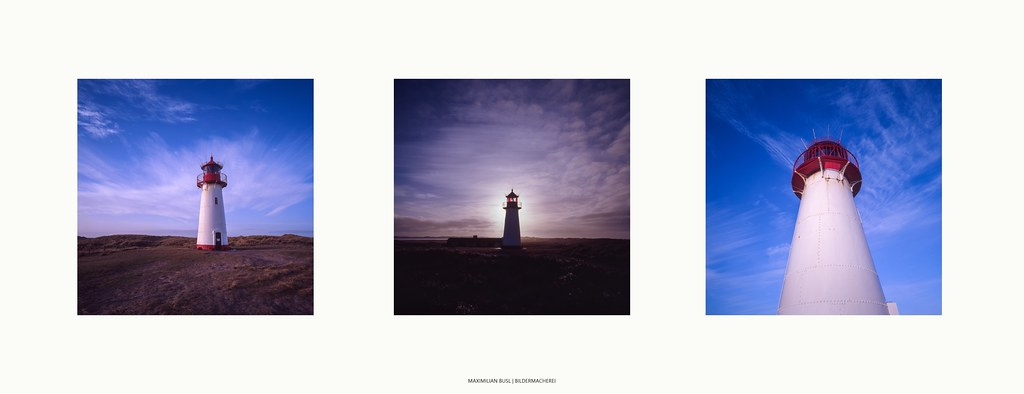

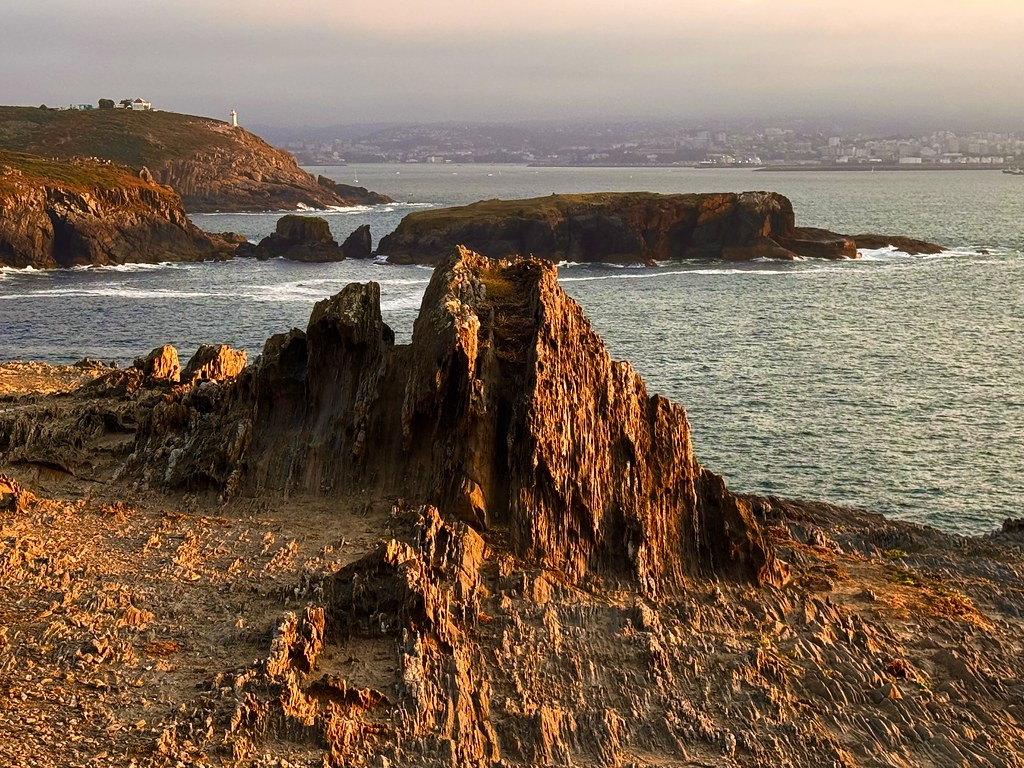

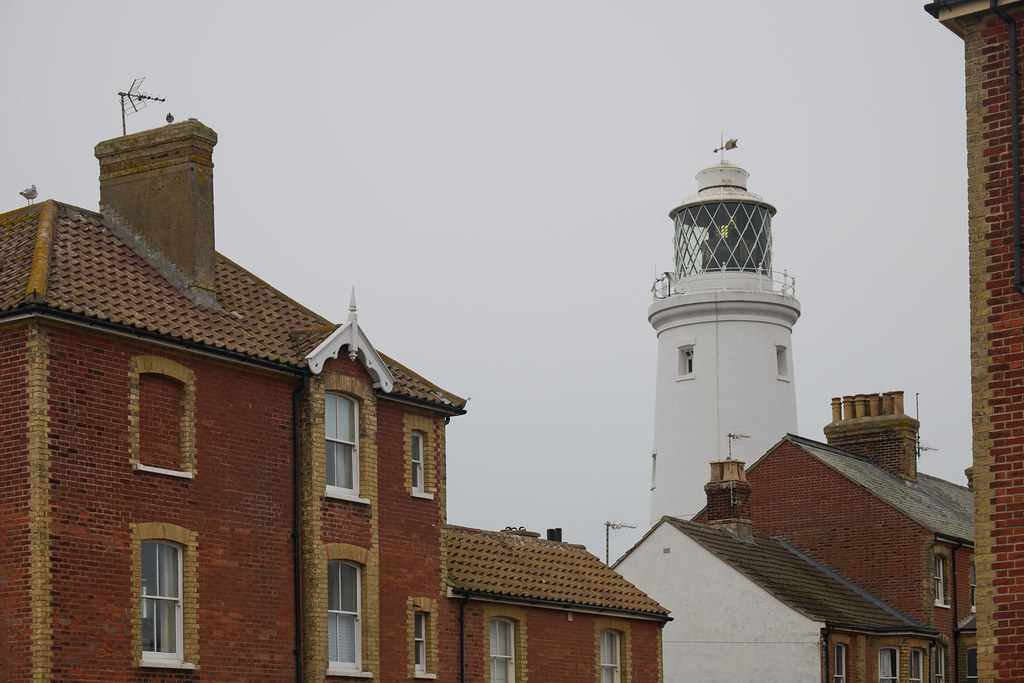

In [8]:
from IPython.display import Image, display

print(df['status'].value_counts().to_string())
print(f"Total downloaded: {df['file_bytes'].sum() / 1e6:.1f} MB")
print(f"Photos with a caption: {(df['caption_text'] != '').sum()} of {len(df)}")

for path in df.loc[df['status'] == 'downloaded', 'file_name'].head(3):
    display(Image(filename=path, width=300))